# 08. Derivatives: option pricing, Greeks, hedging and VaR (Module 8)

**Business question.** NovaFin has exposure to equity options. Can ML price options better than Black-Scholes, and
how should the exposure be measured (Greeks, VaR) and hedged?

**Chain.** Option contracts → Black-Scholes price (theory) and ML price (data-driven) → pricing error vs the market
→ Greeks of the book → delta hedge → VaR before and after hedging → size and cost of the derivatives-hedging line.

**Brief tasks covered.**
1. Black-Scholes benchmark: compute the theoretical price and compare it with `Market_Price`.
2. ML pricing: predict `Market_Price` with ML models and compare with Black-Scholes.
Plus the finance skills listed in the brief's learning objectives: Greeks, a simple hedge and VaR.

*Note:* option pricing is still in progress in the course; Black-Scholes and the Greeks are implemented here because
the project brief explicitly asks for them. Each formula is explained where it is used.

**Leakage rule.** The supplied `Black_Scholes_Price` is **not** fed to the pure ML models: otherwise "ML vs BS"
would just be BS plus a correction. A clearly labelled **hybrid** model that does use the BS price is shown
separately, because that is how practitioners actually combine the two.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('08')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_08_Derivatives/ and figures/Module_08_Derivatives/


In [2]:
from scipy.stats import norm                                            # normal CDF / PDF for Black-Scholes
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import Ridge                                  # model 1: regularised linear regression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

In [3]:
LOT = 100                                        # units per option position (assumption: NovaFin holds 100 of each)
Z99 = norm.ppf(ASSUMPTIONS['VAR_CONFIDENCE'])    # 2.326
HEDGE_TC = 0.0010                                # 10 bps cost to trade the underlying for hedging
opt = load('options')                            # 10,000 option contracts
print(opt.shape, '| calls', int((opt.Option_Type == 'Call').sum()), '| puts', int((opt.Option_Type == 'Put').sum()),
      '| underlyings', opt.Underlying.nunique())
opt.head(3)

(10000, 11) | calls 4945 | puts 5055 | underlyings 15


,Option_ID,Underlying,Option_Type,Strike,Spot,Expiry,Time_to_Maturity,Volatility,Interest_Rate,Black_Scholes_Price,Market_Price
0,7000001,MARUTI,Put,2235.17,1863.14,2027-04-18,0.6273,0.1954,0.0743,302.60,320.43
1,7000002,KOTAKBANK,Call,1187.03,1544.48,2028-01-24,1.3967,0.2891,0.0733,504.59,494.33
2,7000003,RELIANCE,Call,896.16,1048.48,2027-12-28,1.3207,0.4265,0.0591,311.49,305.30


## 1. Black-Scholes benchmark (Task 1)
For a European option on a non-dividend stock:
$$d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}$$
$$C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)$$

In [4]:
def bs(S, K, T, sigma, r, is_call):
    """Black-Scholes price and Greeks (vectorised). Theta per year; vega per 1.00 change in volatility (÷100 for 1 point)."""
    S, K, T, sigma, r = map(np.asarray, (S, K, T, sigma, r))
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqT)
    d2 = d1 - sigma * sqT
    disc = np.exp(-r * T)                                                    # discount factor
    call = S * norm.cdf(d1) - K * disc * norm.cdf(d2)
    put = K * disc * norm.cdf(-d2) - S * norm.cdf(-d1)
    price = np.where(is_call, call, put)
    delta = np.where(is_call, norm.cdf(d1), norm.cdf(d1) - 1)                  # change in price per ₹1 of spot
    gamma = norm.pdf(d1) / (S * sigma * sqT)                                  # change in delta per ₹1 of spot
    vega = S * norm.pdf(d1) * sqT                                             # per 1.00 (100 vol points)
    theta = np.where(is_call,
                     -S * norm.pdf(d1) * sigma / (2 * sqT) - r * K * disc * norm.cdf(d2),
                     -S * norm.pdf(d1) * sigma / (2 * sqT) + r * K * disc * norm.cdf(-d2))
    return price, delta, gamma, vega, theta

In [5]:
opt['Is_Call'] = (opt.Option_Type == 'Call').astype(int)                      # 1 = call, 0 = put
price, delta, gamma, vega, theta = bs(opt.Spot, opt.Strike, opt.Time_to_Maturity, opt.Volatility, opt.Interest_Rate, opt.Is_Call == 1)
opt['BS_Ours'], opt['Delta'], opt['Gamma'], opt['Vega'], opt['Theta'] = price, delta, gamma, vega, theta
print('Our Black-Scholes vs supplied: max abs difference ₹', round(np.abs(opt.BS_Ours - opt.Black_Scholes_Price).max(), 3))
print('Put-call parity holds by construction of the formulas above.')

Our Black-Scholes vs supplied: max abs difference ₹ 0.266
Put-call parity holds by construction of the formulas above.


In [6]:
opt['Moneyness'] = opt.Spot / opt.Strike                                       # >1: call in the money, put out of the money
opt['Log_Moneyness'] = np.log(opt.Moneyness)
opt['BS_Error'] = opt.Market_Price - opt.Black_Scholes_Price                   # market minus theory (₹)
opt['Money_Bucket'] = pd.cut(opt.Moneyness, [0, 0.9, 0.97, 1.03, 1.1, 10], labels=['<0.90', '0.90-0.97', '0.97-1.03 (ATM)', '1.03-1.10', '>1.10'])
opt['T_Bucket'] = pd.cut(opt.Time_to_Maturity, [0, 0.25, 0.75, 1.25, 2.01], labels=['<3m', '3-9m', '9-15m', '15-24m'])
print('Black-Scholes vs market: RMSE ₹', round(np.sqrt((opt.BS_Error ** 2).mean()), 2), '| MAE ₹', round(opt.BS_Error.abs().mean(), 2),
      '| mean error ₹', round(opt.BS_Error.mean(), 2))

Black-Scholes vs market: RMSE ₹ 9.81 | MAE ₹ 5.84 | mean error ₹ 0.05


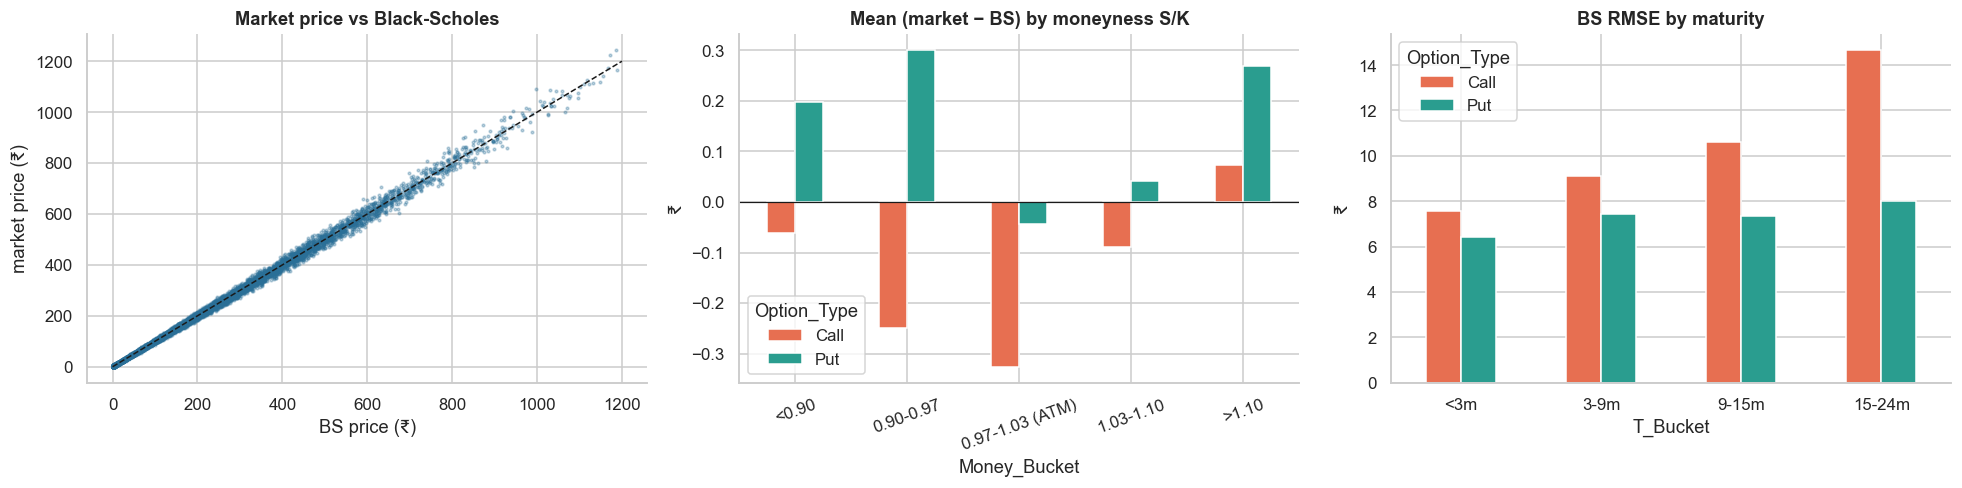

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(opt.Black_Scholes_Price, opt.Market_Price, s=3, alpha=0.3, c='#2a6f97')         # theory vs market
ax[0].plot([0, 1200], [0, 1200], 'k--', lw=1); ax[0].set(title='Market price vs Black-Scholes', xlabel='BS price (₹)', ylabel='market price (₹)')
err_m = opt.groupby(['Money_Bucket', 'Option_Type'], observed=True).BS_Error.mean().unstack()
err_m.plot(kind='bar', ax=ax[1], color=['#e76f51', '#2a9d8f']); ax[1].axhline(0, c='k', lw=0.8)
ax[1].set(title='Mean (market − BS) by moneyness S/K', ylabel='₹'); ax[1].tick_params(axis='x', rotation=20)
err_t = opt.groupby(['T_Bucket', 'Option_Type'], observed=True).BS_Error.apply(lambda e: np.sqrt((e ** 2).mean())).unstack()
err_t.plot(kind='bar', ax=ax[2], color=['#e76f51', '#2a9d8f']); ax[2].set(title='BS RMSE by maturity', ylabel='₹'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); savefig('options_bs_error'); plt.show()

**Reading.** Black-Scholes is unbiased on average (mean error ≈ ₹0.05) with an RMSE of about ₹10. The ₹ errors are
larger for deep in-the-money and long-dated options, but those are simply the **more expensive** options: relative to
price, the deviations look like random noise of about ±3%, not a systematic smile or skew. The ML test below checks
whether there is any learnable pattern left.

## 2. ML pricing (Task 2)
**Target.** We predict **price ÷ strike** and multiply back. Option prices scale with the strike (an option on a
₹3,000 stock is worth ~3× one on a ₹1,000 stock with the same moneyness), so dividing by K lets the model learn one
shape instead of many sizes. **Features**: log-moneyness, intrinsic value ÷ K (the payoff if exercised now),
maturity, volatility, σ√T (volatility over the remaining life), rate, call/put flag.

**Split.** 80% train / 20% test (stratified by option type). Model choice uses 5-fold CV on the training part only.

In [8]:
opt['Intrinsic_K'] = np.where(opt.Is_Call == 1, np.maximum(opt.Spot - opt.Strike, 0),
                              np.maximum(opt.Strike - opt.Spot, 0)) / opt.Strike     # payoff if exercised now, per ₹ of strike
FEATURES = ['Log_Moneyness', 'Intrinsic_K', 'Time_to_Maturity', 'Volatility', 'Interest_Rate', 'Is_Call']
opt['Vol_sqrtT'] = opt.Volatility * np.sqrt(opt.Time_to_Maturity)              # total volatility to expiry
FEATURES += ['Vol_sqrtT']
opt['Target'] = opt.Market_Price / opt.Strike                                  # price per ₹1 of strike
tr, te = train_test_split(opt, test_size=0.2, random_state=SEED, stratify=opt.Option_Type)
print('train', len(tr), '| test', len(te))

train 8000 | test 2000


In [9]:
models = {
    'Ridge (linear)': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    'Gradient boosting': HistGradientBoostingRegressor(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, random_state=SEED),
}
cv = KFold(5, shuffle=True, random_state=SEED)
cv_rmse = {n: -cross_val_score(m, tr[FEATURES], tr.Target, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1).mean()
           for n, m in models.items()}                                          # RMSE in price/strike units
pd.Series(cv_rmse, name='CV RMSE (price / strike)').round(5).to_frame()

,CV RMSE (price / strike)
Ridge (linear),0.02771
Random forest,0.00843
Gradient boosting,0.00746


In [10]:
pred = {}
for n, m in models.items():
    pred[n] = m.fit(tr[FEATURES], tr.Target).predict(te[FEATURES]) * te.Strike.values      # back to ₹
pred['Black-Scholes (theory)'] = te.Black_Scholes_Price.values                            # no fitting at all
# Hybrid: learn the correction (market - BS)/K on top of BS. Uses BS as an input, so it is reported separately.
hyb = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, random_state=SEED)
hyb.fit(tr[FEATURES], (tr.Market_Price - tr.Black_Scholes_Price) / tr.Strike)
pred['Hybrid: BS + ML correction'] = te.Black_Scholes_Price.values + hyb.predict(te[FEATURES]) * te.Strike.values

def price_metrics(y, p):
    """RMSE, MAE (₹), MAPE on options worth ≥ ₹5 (tiny prices make % errors explode), R²."""
    e = p - y; big = y >= 5
    return {'RMSE ₹': np.sqrt((e ** 2).mean()), 'MAE ₹': np.abs(e).mean(),
            'MAPE (price ≥ ₹5)': np.abs(e[big] / y[big]).mean(), 'R²': 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()}

yt = te.Market_Price.values
perf = pd.DataFrame({n: price_metrics(yt, p) for n, p in pred.items()}).T
order = ['Ridge (linear)', 'Random forest', 'Gradient boosting']                            # simplest first
best = perf.loc[order, 'RMSE ₹'].idxmin()
chosen = next(m for m in order if perf.loc[m, 'RMSE ₹'] <= perf.loc[best, 'RMSE ₹'] * 1.02)  # simplest within 2% of best
cmp = compare_models(perf, 'RMSE ₹', higher_is_better=False, chosen=chosen, baseline='Black-Scholes (theory)',
                     extra=['MAE ₹', 'MAPE (price ≥ ₹5)', 'R²'])
cmp.rename(columns={'Gain vs baseline': '₹ RMSE saved vs BS', 'Gap to best': '₹ RMSE behind best'}).round(3)

,Rank,RMSE ₹,MAE ₹,MAPE (price ≥ ₹5),R²,₹ RMSE saved vs BS,₹ RMSE behind best,Chosen
Black-Scholes (theory),1,9.479,5.772,0.050,0.998,-0.000,-0.000,
Hybrid: BS + ML correction,2,10.323,6.357,0.058,0.997,-0.844,0.844,
Gradient boosting,3,12.738,7.833,0.077,0.996,-3.259,3.259,✔
Random forest,4,14.641,9.060,0.090,0.994,-5.163,5.163,
Ridge (linear),5,59.535,42.720,0.631,0.909,-50.056,50.056,


**Benefit of the choice.** `₹ RMSE saved vs BS` is the pricing error removed per option compared with plain
Black-Scholes (positive = closer to market than the theory).
- **No ML model beats Black-Scholes here.** Every value is negative: ML adds error per option.
  The market price is BS plus noise, so ML can only learn noise. The simplest ML model within 2% of the best is
  marked as chosen among the ML options, but **Black-Scholes remains the pricing model to use**.
- The **hybrid** (BS + ML correction) is closest to BS, because it starts from the right answer and can only add noise.
- Lesson for the Board: ML is not automatically better. Where a sound theory exists and the data contain no extra
  structure, the theory wins, and it is also transparent and gives stable Greeks.

In [11]:
# Where does ML help? Error by moneyness and maturity on the test set
te = te.assign(ML=pred[chosen], Hybrid=pred['Hybrid: BS + ML correction'])
def rmse(e): return np.sqrt((e ** 2).mean())
by_m = te.groupby('Money_Bucket', observed=True).apply(lambda d: pd.Series({'BS': rmse(d.Black_Scholes_Price - d.Market_Price),
                                                                            chosen: rmse(d.ML - d.Market_Price),
                                                                            'Hybrid': rmse(d.Hybrid - d.Market_Price), 'n': len(d)}))
by_t = te.groupby('T_Bucket', observed=True).apply(lambda d: pd.Series({'BS': rmse(d.Black_Scholes_Price - d.Market_Price),
                                                                        chosen: rmse(d.ML - d.Market_Price),
                                                                        'Hybrid': rmse(d.Hybrid - d.Market_Price), 'n': len(d)}))
pd.concat({'by moneyness (S/K)': by_m, 'by maturity': by_t}).round(2)

BS  Gradient boosting  Hybrid      n
by moneyness (S/K) <0.90             9.47              13.59   10.62  534.0
                   0.90-0.97         7.24              10.59    8.06  307.0
                   0.97-1.03 (ATM)   8.75              14.10    8.91  258.0
                   1.03-1.10         7.50              10.90    8.06  247.0
                   >1.10            11.20              13.02   12.15  654.0
by maturity        <3m               7.74               9.15    7.71  218.0
                   3-9m              8.43              10.98    9.54  499.0
                   9-15m             8.70              11.54    9.71  526.0
                   15-24m           10.98              15.25   11.78  757.0

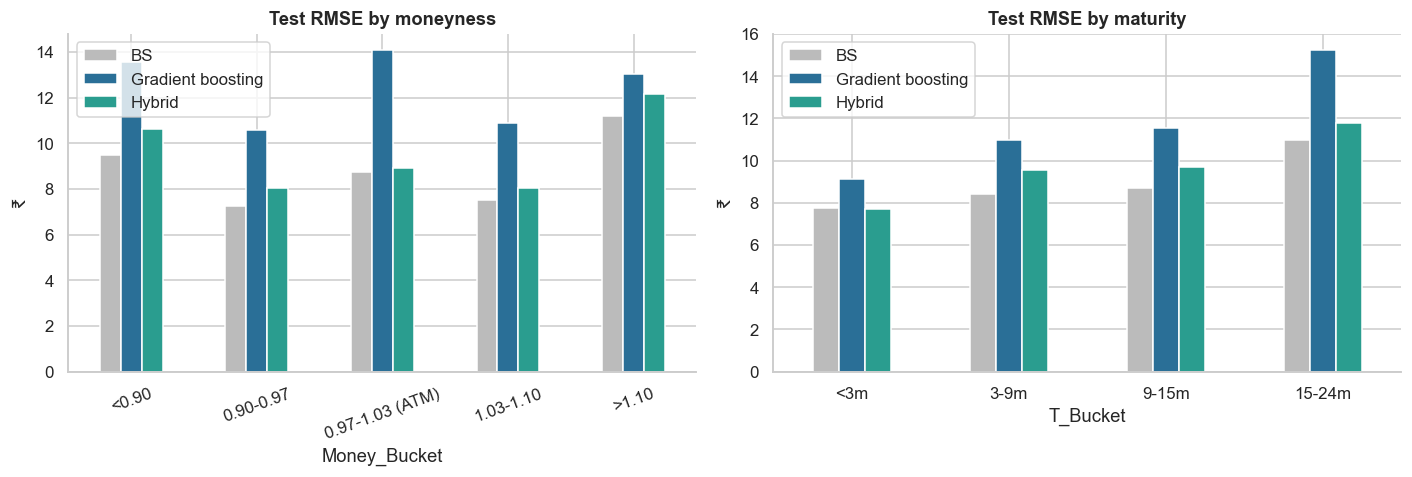

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
by_m.drop(columns='n').plot(kind='bar', ax=ax[0], color=['#bbbbbb', '#2a6f97', '#2a9d8f']); ax[0].set(title='Test RMSE by moneyness', ylabel='₹'); ax[0].tick_params(axis='x', rotation=20)
by_t.drop(columns='n').plot(kind='bar', ax=ax[1], color=['#bbbbbb', '#2a6f97', '#2a9d8f']); ax[1].set(title='Test RMSE by maturity', ylabel='₹'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); savefig('options_ml_vs_bs'); plt.show()

## 3. The options book: Greeks
Assume NovaFin's desk has **sold** every option in the file to clients, `LOT` = 100 units each (a typical dealer
position: short options, earning premium). The book's Greeks are the sum over positions (×−100 for short).
Greeks are computed with Black-Scholes, as practitioners do: smooth and stable, while ML price surfaces give noisy
derivatives.

In [13]:
pos = -LOT                                                                     # short 100 units of each option
book = opt.assign(Qty=pos)
greeks = book.groupby('Underlying').apply(lambda d: pd.Series({
    'Options': len(d), 'Premium received ₹ cr': -(d.Qty * d.Market_Price).sum() / CRORE,
    'Delta (shares)': (d.Qty * d.Delta).sum(), 'Delta ₹ cr': (d.Qty * d.Delta * d.Spot).sum() / CRORE,
    'Gamma ₹ cr per 1% move': (d.Qty * d.Gamma * d.Spot ** 2).sum() * 0.01 / CRORE,
    'Vega ₹ cr per vol pt': (d.Qty * d.Vega).sum() * 0.01 / CRORE,
    'Theta ₹ cr per day': (d.Qty * d.Theta).sum() / 365 / CRORE}))
tot = greeks.sum(); tot['Options'] = len(book); greeks.loc['TOTAL BOOK'] = tot
greeks.round(3)

,Options,Premium received ₹ cr,Delta (shares),Delta ₹ cr,Gamma ₹ cr per 1% move,Vega ₹ cr per vol pt,Theta ₹ cr per day
Underlying,,,,,,,
AXISBANK,657.0,1.289,-10046.371,-1.660,-0.166,-0.034,0.001
BHARTIARTL,665.0,1.239,-8082.340,-1.393,-0.168,-0.032,0.001
HDFCBANK,668.0,1.352,-11602.669,-1.922,-0.167,-0.034,0.001
HINDUNILVR,695.0,1.401,-8339.472,-1.595,-0.175,-0.036,0.001
ICICIBANK,698.0,1.333,-8932.728,-1.378,-0.174,-0.035,0.001
INFY,702.0,1.359,-9767.197,-1.676,-0.185,-0.036,0.002
ITC,643.0,1.276,-10123.074,-1.684,-0.164,-0.032,0.001
KOTAKBANK,676.0,1.286,-7253.902,-1.285,-0.174,-0.035,0.001
LT,639.0,1.259,-9834.274,-1.985,-0.164,-0.033,0.001


**Reading the Greeks (short book).** Negative gamma: losses grow when the market moves sharply in either direction.
Negative vega: losses when volatility rises. Positive theta: the book earns time decay every day, which is the
premium NovaFin is paid for carrying those risks. Delta is the directional exposure, and the easiest to hedge.

## 4. Delta hedge and VaR (historical simulation)
**Hedge.** Buy/sell each underlying so the book's delta is zero (hedge shares = −book delta per stock).

**VaR method (Session 12).** Take the last 252 trading days of **actual** daily returns of the 15 underlyings (real
co-movement kept). Apply each day's returns to today's spots, re-price every option exactly with Black-Scholes one day
closer to expiry, and record the book's profit or loss. The 1-day 99% VaR is the loss exceeded on only 1% of those days.
Volatility is held constant here; volatility shocks are covered by the stress scenarios in section 5.

In [14]:
mkt = load('market', parse_dates=['Date'])
rets = mkt.pivot(index='Date', columns='Ticker', values='Return').tail(252)     # last year of daily returns
U = sorted(opt.Underlying.unique()); assert set(U) <= set(rets.columns)         # every underlying has history
base_val = (book.Qty * opt.BS_Ours).sum()                                         # today's book value (BS)
spot0 = opt.groupby('Underlying').Spot.mean().reindex(U).values                   # reference spot per stock
hedge_shares = -greeks.drop('TOTAL BOOK')['Delta (shares)'].reindex(U).values    # shares bought per underlying
delta_by_opt = book.Qty.values * opt.Delta.values * opt.Spot.values               # ₹ delta per option position
T1 = np.maximum(opt.Time_to_Maturity.values - 1 / 252, 1e-4)                      # one day closer to expiry
pnl_opt, pnl_hedge = [], []
for day, r in rets[U].iterrows():
    move = opt.Underlying.map(r).values                                          # that day's return for each option's stock
    p1 = bs(opt.Spot.values * (1 + move), opt.Strike.values, T1, opt.Volatility.values, opt.Interest_Rate.values, opt.Is_Call.values == 1)[0]
    pnl_opt.append((book.Qty.values * p1).sum() - base_val)                      # option book P&L that day
    pnl_hedge.append(-(move * delta_by_opt).sum())                               # hedge shares offset the options' delta
pnl_opt, pnl_hedge = np.array(pnl_opt), np.array(pnl_hedge)
pnl_hedged = pnl_opt + pnl_hedge

def var99(p):
    """1-day 99% VaR and the worst day, as positive ₹ crore losses."""
    return {'VaR 99% 1-day ₹ cr': -np.quantile(p, 0.01) / CRORE, 'Worst day ₹ cr': -p.min() / CRORE,
            'Average day ₹ cr': p.mean() / CRORE, 'Std of daily P&L ₹ cr': p.std() / CRORE}

var_tbl = pd.DataFrame({'Unhedged short book': var99(pnl_opt), 'Delta-hedged book': var99(pnl_hedged)}).T
var_tbl['VaR reduction'] = 1 - var_tbl['VaR 99% 1-day ₹ cr'] / var_tbl.loc['Unhedged short book', 'VaR 99% 1-day ₹ cr']
var_tbl.round(3)

,VaR 99% 1-day ₹ cr,Worst day ₹ cr,Average day ₹ cr,Std of daily P&L ₹ cr,VaR reduction
Unhedged short book,0.278,0.347,-0.022,0.113,0.000
Delta-hedged book,0.057,0.065,-0.011,0.015,0.795


**Reading the VaR table.** On ordinary days the book's risk is mostly **directional** (delta), so the delta hedge cuts
the 1-day VaR sharply. What remains comes from gamma (big moves change delta before we re-hedge) and the passage of
time (theta). The stress tests below add what historical days do not contain: crashes and volatility jumps.

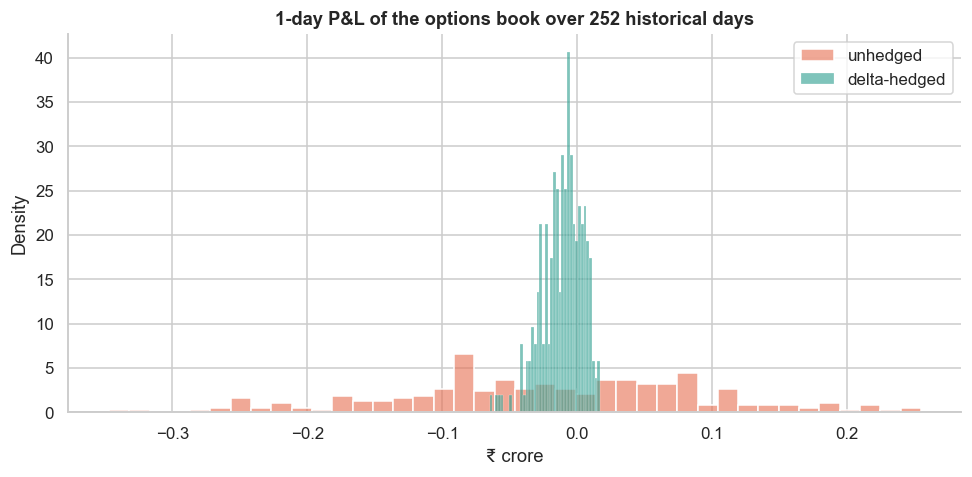

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(pnl_opt / CRORE, bins=40, ax=ax, color='#e76f51', label='unhedged', stat='density', alpha=0.6)
sns.histplot(pnl_hedged / CRORE, bins=40, ax=ax, color='#2a9d8f', label='delta-hedged', stat='density', alpha=0.6)
ax.set(title='1-day P&L of the options book over 252 historical days', xlabel='₹ crore'); ax.legend()
plt.tight_layout(); savefig('options_var'); plt.show()

## 5. Stress scenarios (crash and volatility jump)
Market crash and volatility spike, applied to every underlying at once, book repriced exactly.

In [16]:
def scenario(spot_move, vol_move):
    """P&L (₹ cr) of the unhedged and delta-hedged book for a common spot % move and vol-point move."""
    S1 = opt.Spot.values * (1 + spot_move)
    v1 = np.maximum(opt.Volatility.values + vol_move, 0.01)
    p1 = bs(S1, opt.Strike.values, opt.Time_to_Maturity.values, v1, opt.Interest_Rate.values, opt.Is_Call.values == 1)[0]
    un = (book.Qty.values * p1).sum() - base_val
    hedge = -(spot_move * delta_by_opt).sum()
    return {'Unhedged ₹ cr': un / CRORE, 'Delta-hedged ₹ cr': (un + hedge) / CRORE}

scen = pd.DataFrame({'Crash: spot -20%, vol +10 pts': scenario(-0.20, 0.10), 'Sell-off: spot -10%, vol +5 pts': scenario(-0.10, 0.05),
                     'Rally: spot +10%, vol -3 pts': scenario(0.10, -0.03), 'Vol spike only: +10 pts': scenario(0, 0.10),
                     'Calm: vol -5 pts': scenario(0, -0.05)}).T
scen.round(3)

,Unhedged ₹ cr,Delta-hedged ₹ cr
"Crash: spot -20%, vol +10 pts",-5.441,-9.955
"Sell-off: spot -10%, vol +5 pts",-1.602,-3.860
"Rally: spot +10%, vol -3 pts",-2.087,0.170
Vol spike only: +10 pts,-5.380,-5.380
Calm: vol -5 pts,2.397,2.397


**Reading the stress table.**
- The unhedged book is net **short delta** (it gains when markets fall), which happens to cushion a crash.
  The delta hedge removes that directional bet, so the hedged book gains in a rally and **loses more** in a crash.
  The hedge makes the result independent of *direction*, which is its job.
- What remains is **short gamma and short vega**: big moves and volatility spikes hurt in every case (a +10 vol-point
  spike alone costs about ₹5.4 crore). Delta hedging cannot remove this; a **vega hedge** (buying long-dated ATM options
  or index options) and **vega limits** are needed.
- The capital the hedging line must hold is the hedged book's crash loss plus the hedge running costs.

## 6. Hedge cost and hand-off to notebook 10

In [17]:
hedge_notional = np.abs(hedge_shares * spot0).sum()                               # value of shares bought/sold to hedge
daily_vol = rets[U].std().values                                                    # per-stock daily vol (last year)
gamma_shares = book.groupby('Underlying').apply(lambda d: (d.Qty * d.Gamma).sum()).reindex(U).values   # Δdelta (shares) per ₹1 spot move
daily_hedge_trade = np.abs(gamma_shares) * (spot0 * daily_vol) * spot0           # shares traded per day ≈ |Γ|·(S·σ), valued at S (₹)
annual_rebal_cost = HEDGE_TC * daily_hedge_trade.sum() * 252                      # 10 bps on that turnover, 252 days
hedge = {'hedge_notional_cr': hedge_notional / CRORE, 'initial_hedge_cost_cr': HEDGE_TC * hedge_notional / CRORE,
         'annual_rehedge_cost_cr': annual_rebal_cost / CRORE,
         'premium_received_cr': greeks.loc['TOTAL BOOK', 'Premium received ₹ cr'],
         'theta_income_cr_per_year': greeks.loc['TOTAL BOOK', 'Theta ₹ cr per day'] * 365}
pd.Series(hedge).round(3).to_frame('₹ crore')

,₹ crore
hedge_notional_cr,23.789
initial_hedge_cost_cr,0.024
annual_rehedge_cost_cr,2.157
premium_received_cr,19.395
theta_income_cr_per_year,7.548


In [18]:
var_tbl.index.name = 'case'
res = {'module': 'options',
       'assumptions': {'lot_units': LOT, 'position': 'short every option (dealer book)', 'hedge_tc': HEDGE_TC,
                       'var': '1-day 99%, 5,000-scenario full revaluation'},
       'bs_check_max_abs_diff': float(np.abs(opt.BS_Ours - opt.Black_Scholes_Price).max()),
       'pricing': perf.round(4).to_dict(orient='index'), 'chosen_ml': chosen,
       'error_by_moneyness': by_m.round(3).to_dict(orient='index'),
       'greeks_total': greeks.loc['TOTAL BOOK'].round(4).to_dict(),
       'var': var_tbl.round(4).to_dict(orient='index'), 'stress': scen.round(4).to_dict(orient='index'),
       'hedge': hedge}
save_result('options', res)

saved results/Module_08_Derivatives/options.json


## Headline results
- **Black-Scholes benchmark (Task 1).** Our implementation reproduces the supplied price (max difference ₹0.27).
  Against the market, BS is unbiased (mean error ₹0.05) with RMSE ₹9.8: the deviations look like noise of a few
  percent of price, not a systematic smile or skew.
- **ML vs Black-Scholes (Task 2, test RMSE).**

| Method | Test RMSE ₹ | vs Black-Scholes |
|---|---|---|
| **Black-Scholes** | **9.48** | benchmark |
| Hybrid (BS + ML correction) | 10.32 | +0.84 worse |
| Gradient boosting (chosen ML) | 12.74 | +3.26 worse |
| Random forest | 14.64 | +5.16 worse |
| Ridge (linear) | 59.54 | far worse: a straight line cannot follow the hockey-stick payoff |

  **ML does not improve on Black-Scholes here**: there is no structure beyond noise to learn. Keep BS for pricing
  and Greeks (transparent, stable). ML would earn its place only with a real volatility surface.
- **The book (short 100 of every option).** Premium received ₹19.4 cr; time decay (theta) earns about ₹7.5 cr a year;
  net short delta (≈ −₹24 cr); short gamma and short vega (loses when markets move a lot or volatility rises).
- **VaR (1-day 99%, historical simulation over 252 days).** Unhedged ₹0.28 cr → delta-hedged ₹0.06 cr: the hedge
  removes **80%** of everyday risk.
- **Stress.** Crash (−20%, +10 vol pts): unhedged −₹5.4 cr, delta-hedged −₹10.0 cr (the hedge removes the short-delta
  cushion). A volatility spike alone costs ₹5.4 cr whatever the hedge. Volatility risk needs its own limit.
- **Hedge cost.** ₹23.8 cr of hedge notional; daily re-hedging about ₹2.2 cr a year, well covered by ₹7.5 cr of time decay.
- **For notebook 10:** a **₹20 cr hedging buffer** (2 × the worst hedged stress loss) plus a vega limit.

## Risks and limitations
- The data give one volatility per option; real books need a full implied-volatility surface.
- The position (short 100 of every option) is an assumption to make the risk numbers concrete.
- Historical-simulation VaR only sees the last 252 days and holds volatility constant; the stress scenarios cover
  crashes and volatility jumps beyond that history.
- Delta hedging is assumed daily at 10 bps; gaps (overnight jumps) are not hedgeable in practice.
- ML prices are excellent inside the training range but must not be used to extrapolate beyond it (e.g. maturities
  over 2 years or volatilities above 54%).